In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split

plt.style.use("dark_background")
np.random.seed(42)
print("Ready!")

Ready!


---

# 1. Data Visualization Fundamentals

**Why Visualize?**

- Understand data distribution
- Detect outliers
- Identify relationships between features
- Make informed preprocessing decisions


In [3]:
housing = fetch_california_housing()
X_data = housing.data
y_target = housing.target

print(housing.feature_names)

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


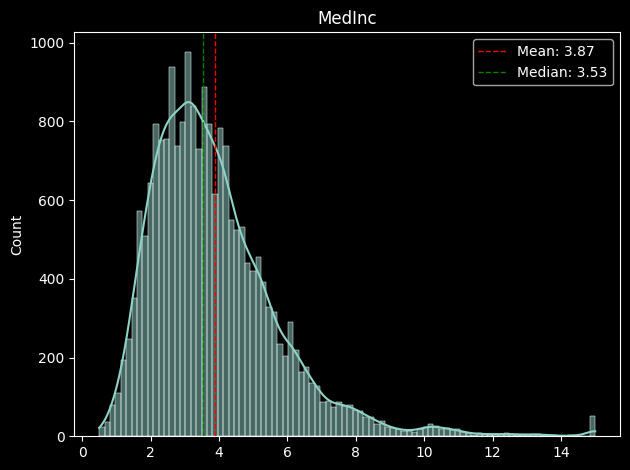

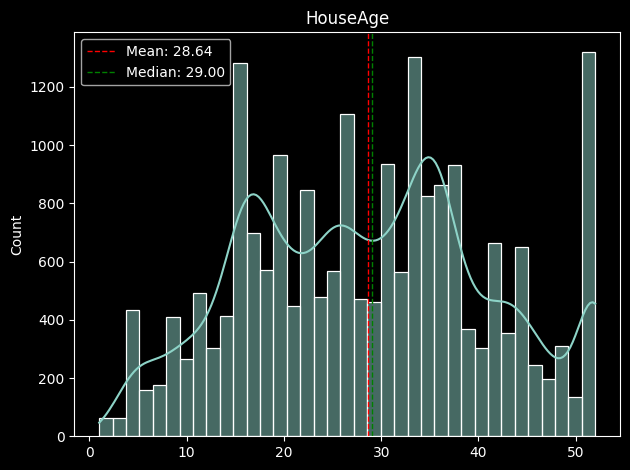

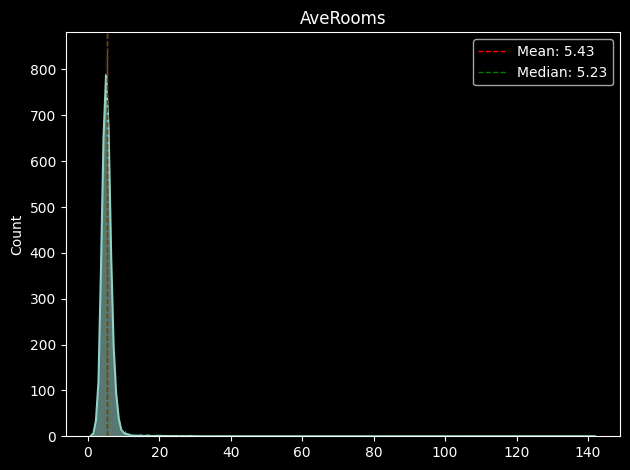

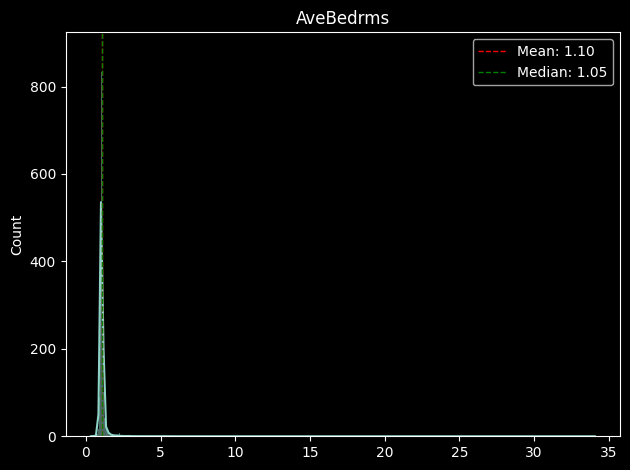

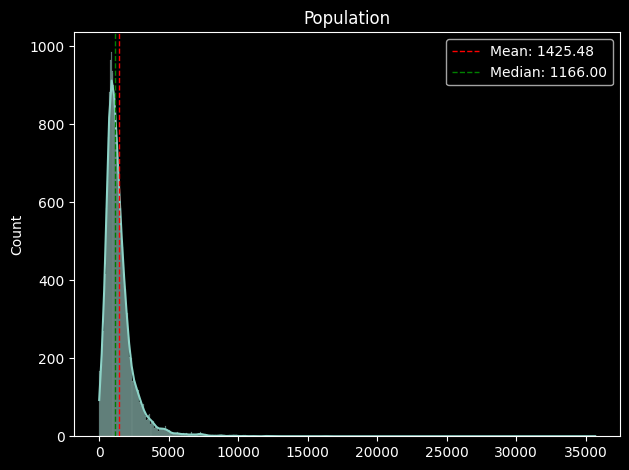

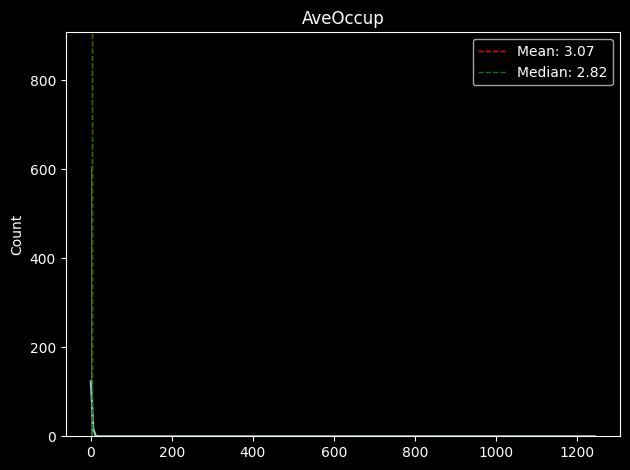

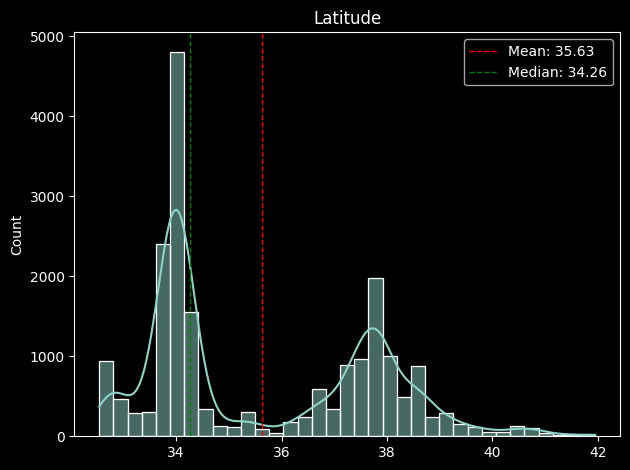

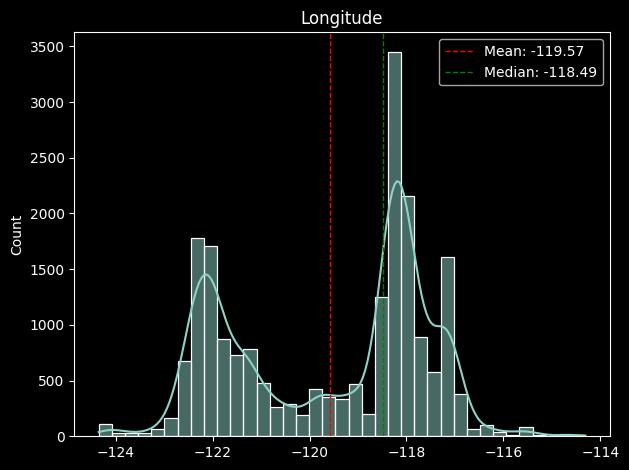

In [4]:
for col in range(X_data.shape[1]):
    sns.histplot(X_data[:, col], kde=True)
    
    
    mean_col = np.mean(X_data[:, col])
    median_col = np.median(X_data[:, col])
    
    plt.axvline(mean_col, color="red", linewidth=1, linestyle="--", label=f"Mean: {mean_col:.2f}")
    plt.axvline(median_col, color="green", linewidth=1, linestyle="--", label=f"Median: {median_col:.2f}")
    # plt.axvline(np.std(X_data[:, col]), color="blue", linewidth=1, linestyle="--")
    
    plt.title(f"{housing.feature_names[col]}")
    
    plt.tight_layout()
    plt.legend()
    plt.show()

As I expected. when we look at the two distributions of the last two features, we find that they are a bit similar which means they might be highly correlated (Mullticollinearity). And when we look at the next cell and see the correlation between them, we find that our conclusion is correct

The have a high negative linear relationship

In [5]:
print(np.corrcoef(X_data[:, 6], X_data[:, 7]))

[[ 1.         -0.92466443]
 [-0.92466443  1.        ]]


We observe that there is high density at x = 5 like if there were so many outliers and they were capped

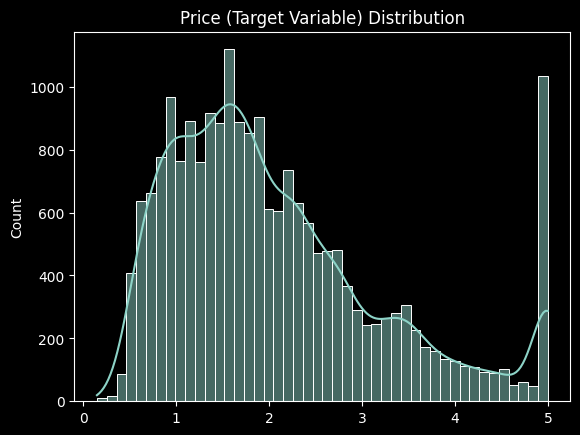

In [6]:
# The target distribution
sns.histplot(y_target, kde=True)
plt.title("Price (Target Variable) Distribution")
plt.show()

In [7]:
# Load California Housing dataset
df_housing = pd.DataFrame(housing.data, columns=housing.feature_names)
df_housing["Price"] = y_target

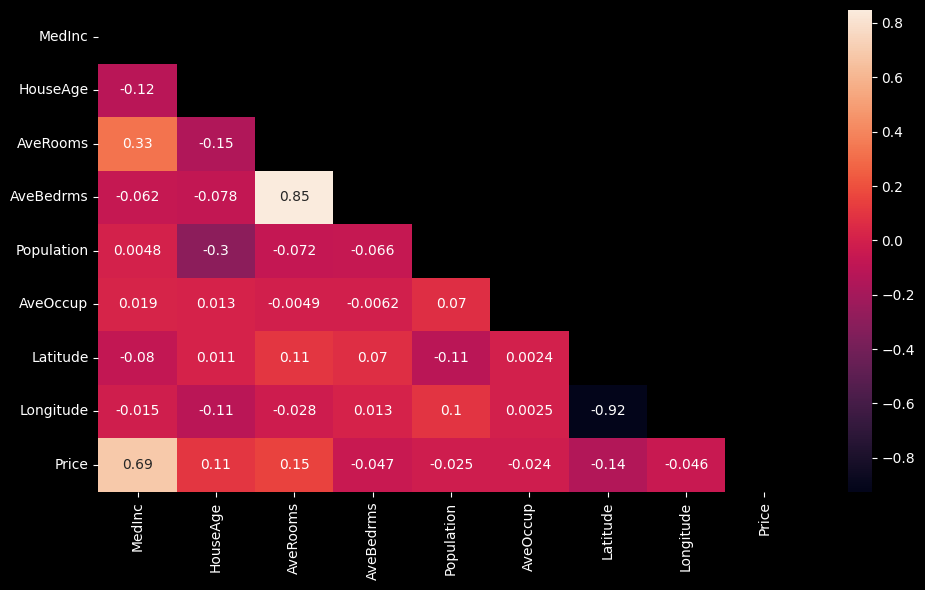

In [97]:
plt.figure(figsize=(10, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(df_housing.corr(), annot=True, mask=mask)
plt.tight_layout()
plt.show()

---

In [9]:
# Load California Housing dataset
df_housing = pd.DataFrame(housing.data, columns=housing.feature_names)
df_housing["Price"] = y_target

print(df_housing.shape)
print(df_housing.columns.tolist())
df_housing.head()

(20640, 9)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'Price']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [10]:
df_housing.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


### Distribution Analysis

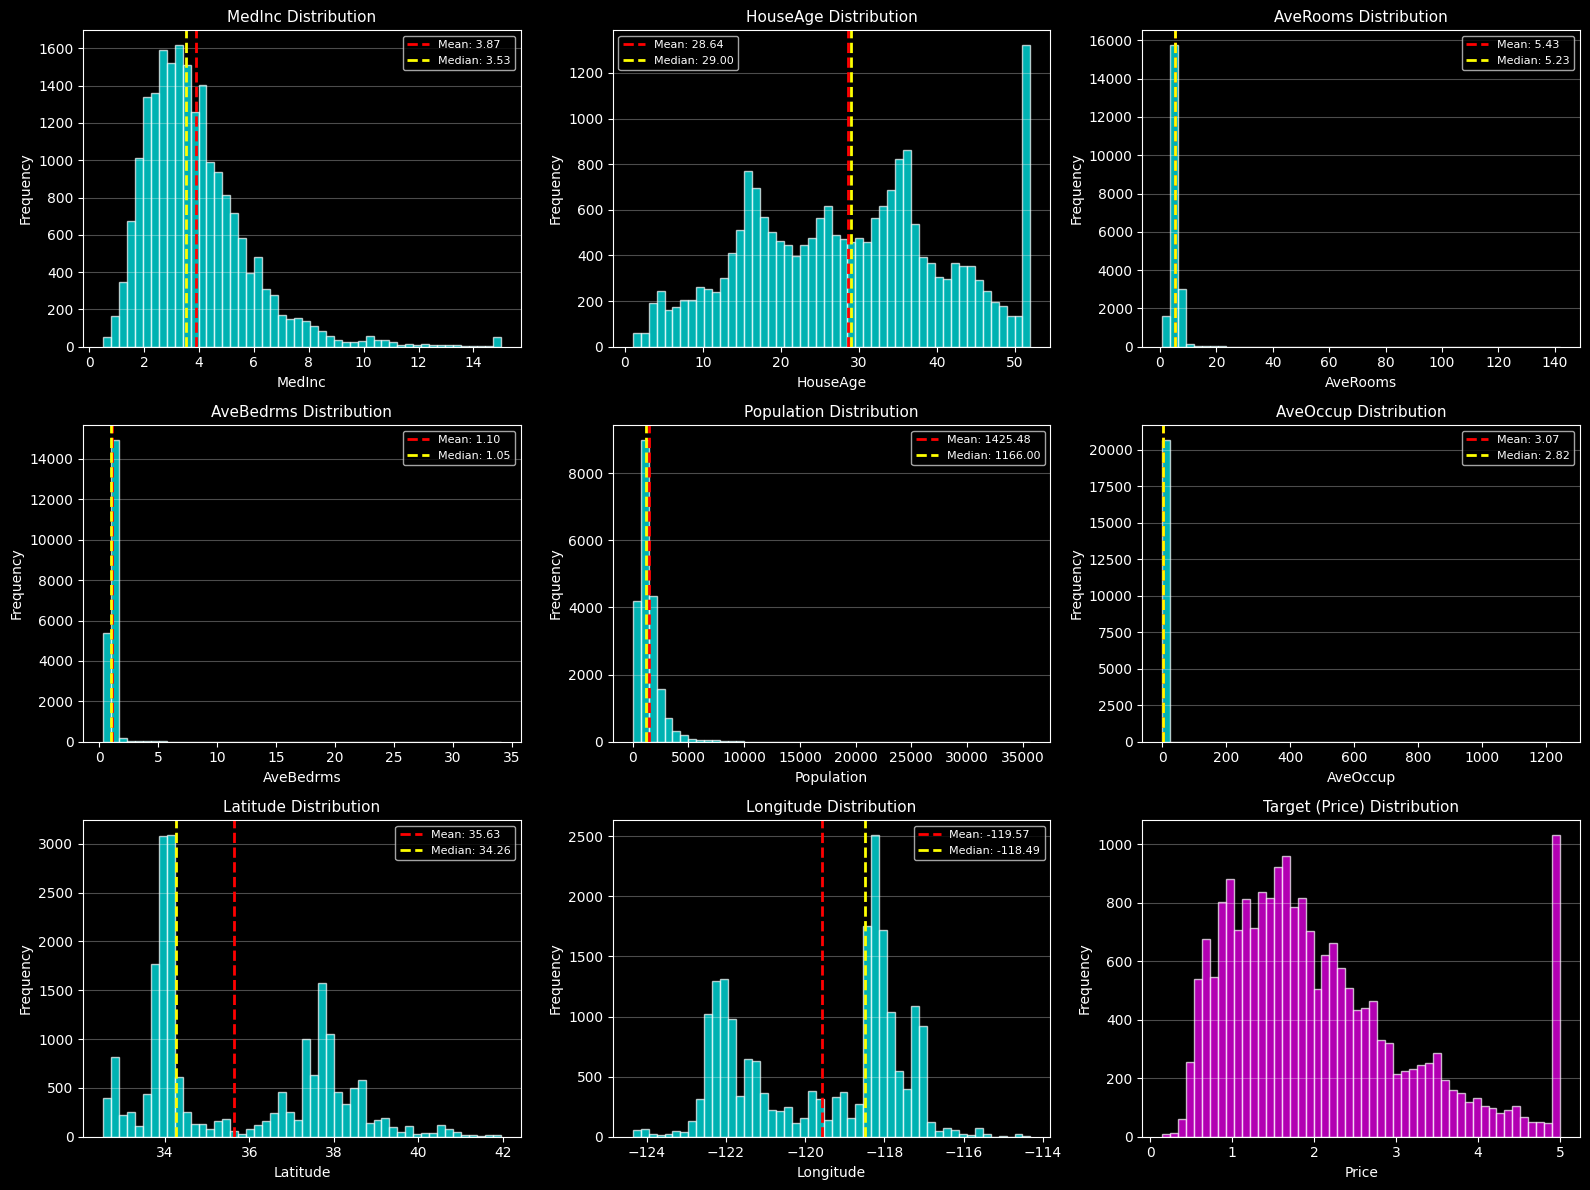

In [11]:
# Feature distributions
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(housing.feature_names):
    axes[i].hist(df_housing[col], bins=50, alpha=0.7, color='cyan', edgecolor='white')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    axes[i].set_title(f'{col} Distribution', fontsize=11)
    axes[i].grid(alpha=0.3, axis='y')

    # Add mean and median lines
    mean_val = df_housing[col].mean()
    median_val = df_housing[col].median()
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=2,
                    label=f'Mean: {mean_val:.2f}')
    axes[i].axvline(median_val, color='yellow', linestyle='--', linewidth=2,
                    label=f'Median: {median_val:.2f}')
    axes[i].legend(fontsize=8)

# Target distribution
axes[8].hist(df_housing['Price'], bins=50, alpha=0.7, color='magenta', edgecolor='white')
axes[8].set_xlabel('Price', fontsize=10)
axes[8].set_ylabel('Frequency', fontsize=10)
axes[8].set_title('Target (Price) Distribution', fontsize=11)
axes[8].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

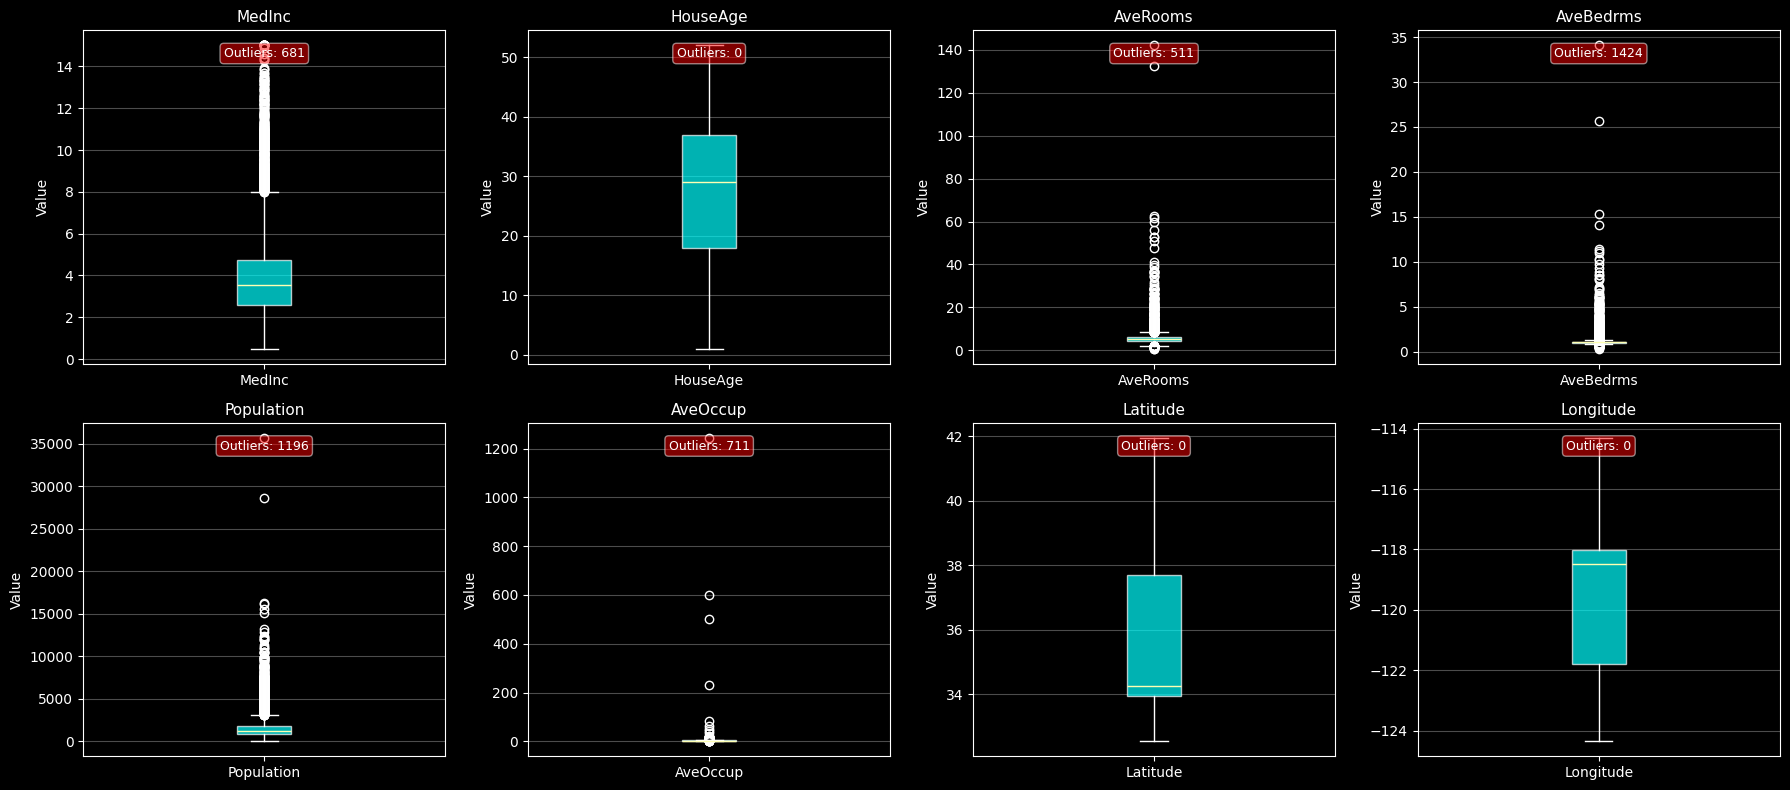

In [12]:
# Box plots for outlier detection
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(housing.feature_names):
    bp = axes[i].boxplot([df_housing[col]], tick_labels=[col], patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('cyan')
        patch.set_alpha(0.7)
    axes[i].set_ylabel('Value', fontsize=10)
    axes[i].set_title(f'{col}', fontsize=11)
    axes[i].grid(alpha=0.3, axis='y')
    
    Q1 = df_housing[col].quantile(0.25)
    Q3 = df_housing[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = ((df_housing[col] < lower_bound) | (df_housing[col] > upper_bound)).sum()
    axes[i].text(0.5, 0.95, f'Outliers: {outliers}',
                 transform=axes[i].transAxes, ha='center', va='top',
                 bbox=dict(boxstyle='round', facecolor='red', alpha=0.5), fontsize=9)

plt.tight_layout()
plt.show()

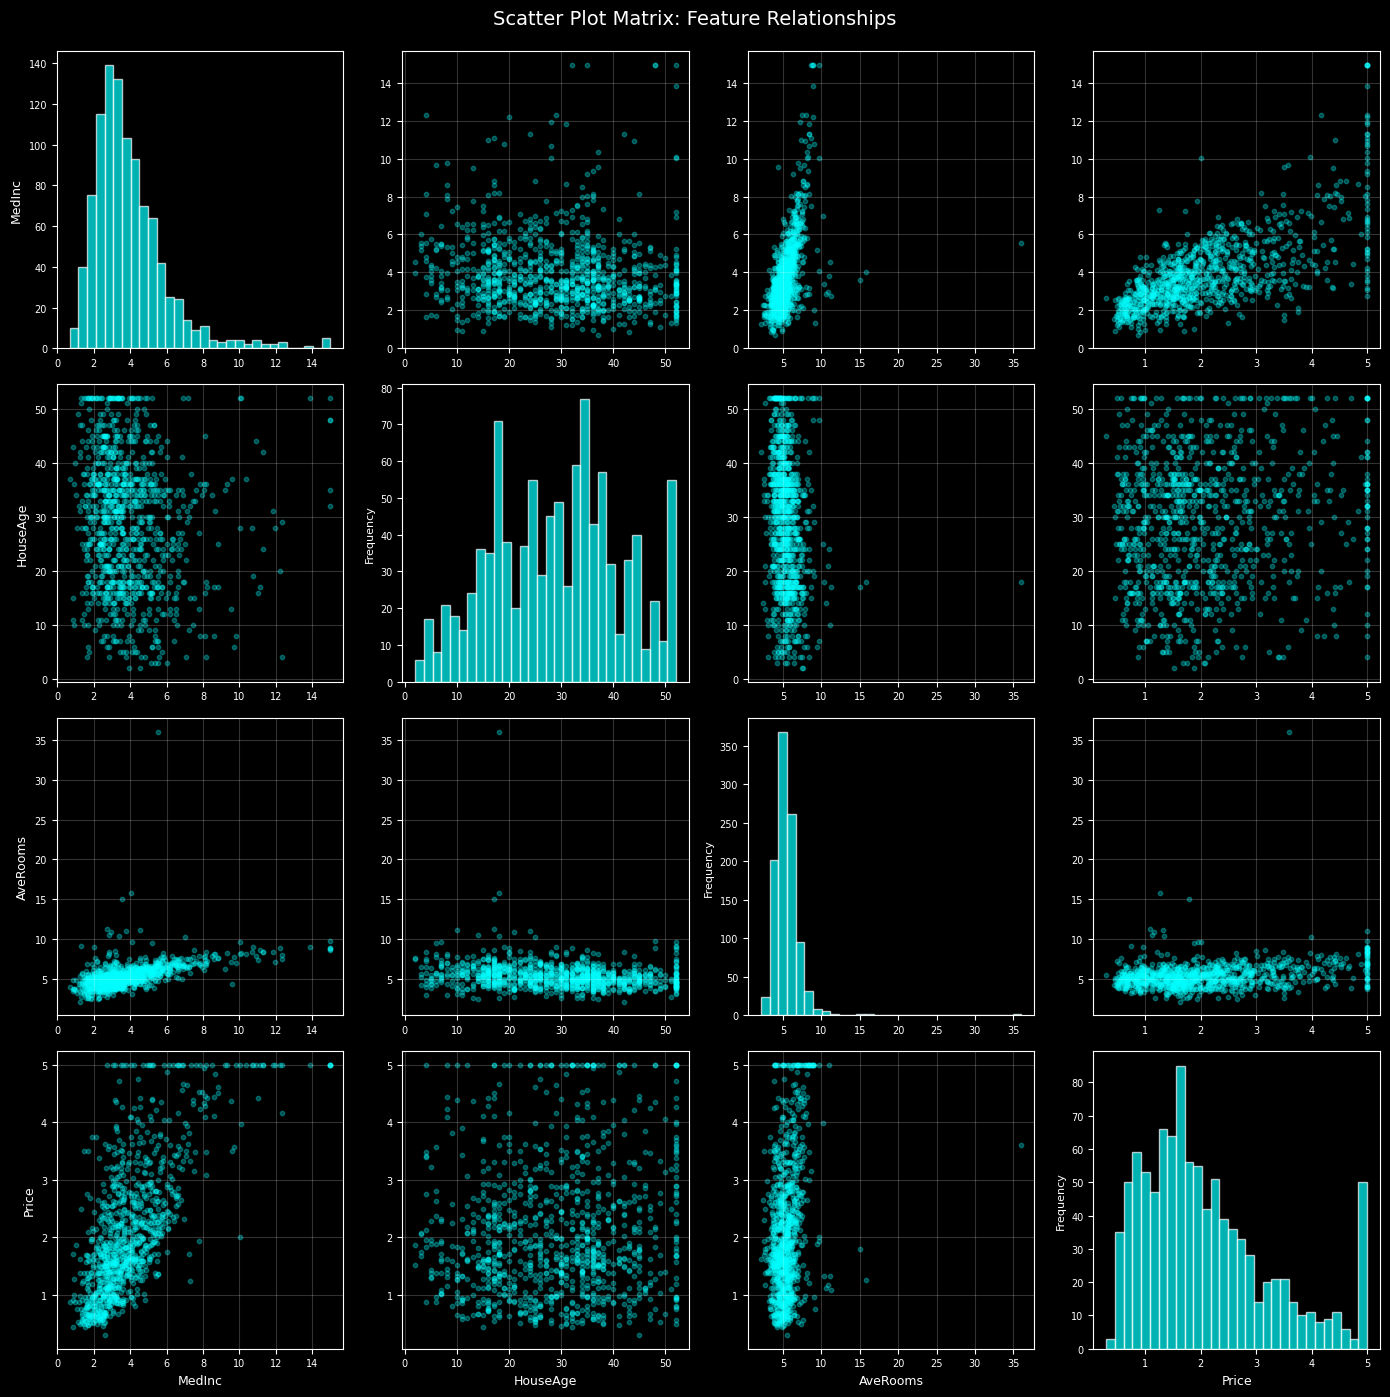

In [13]:
# Scatter plot matrix (subset of features for clarity)
features_subset = ['MedInc', 'HouseAge', 'AveRooms', 'Price']
df_subset = df_housing[features_subset].sample(1000, random_state=42)

fig = plt.figure(figsize=(14, 14))
n_features = len(features_subset)

for i in range(n_features):
    for j in range(n_features):
        ax = plt.subplot(n_features, n_features, i * n_features + j + 1)

        if i == j:
            # Diagonal: notice that correlation would be highest because this is the feature with itself so instead we put histograms here
            # see how this figure captures many things at once
            ax.hist(df_subset.iloc[:, i], bins=30, color='cyan', alpha=0.7, edgecolor='white')
            ax.set_ylabel('Frequency', fontsize=8)
        else:
            # Off-diagonal: scatter plots
            ax.scatter(df_subset.iloc[:, j], df_subset.iloc[:, i],
                       alpha=0.3, s=10, color='cyan')
            ax.grid(alpha=0.2)

        # Labels
        if i == n_features - 1:
            ax.set_xlabel(features_subset[j], fontsize=9)
        if j == 0:
            ax.set_ylabel(features_subset[i], fontsize=9)

        ax.tick_params(labelsize=7)

plt.suptitle('Scatter Plot Matrix: Feature Relationships', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

### Exercise 1: Create Box Plots

**Task:** Create box plots for the Diabetes dataset to identify outliers.


In [14]:
from sklearn.datasets import load_diabetes

diabetes_data = load_diabetes()
X_diabetes_data = diabetes_data.data
y_diabetes_target = diabetes_data.target

diabetes_df = pd.DataFrame(X_diabetes_data, columns=diabetes_data.feature_names)
diabetes_df["target"] = y_diabetes_target

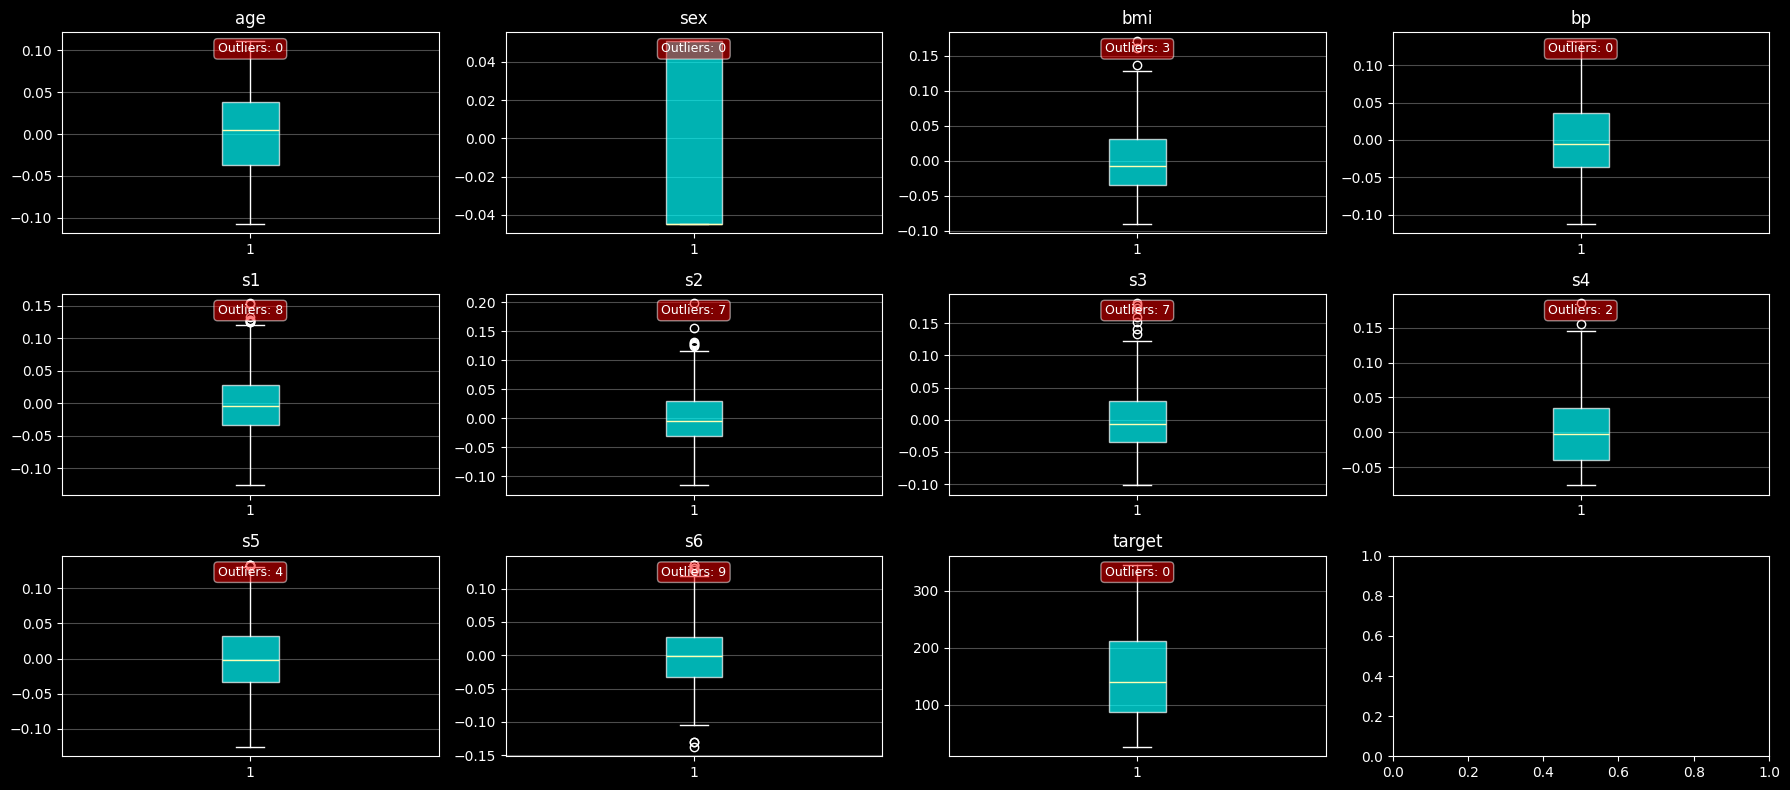

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(diabetes_df.columns):
    bp = axes[i].boxplot([diabetes_df[col]], patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor("cyan")
        patch.set_alpha(0.7)
    axes[i].set_title(col)
    axes[i].grid(alpha=0.3, axis="y")
    
    Q1 = diabetes_df[col].quantile(0.25)
    Q3 = diabetes_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = diabetes_df[(diabetes_df[col] < lower_bound) | (diabetes_df[col] > upper_bound)][col].shape[0]
    # outliers = ((diabetes_df[col] < lower_bound) | (diabetes_df[col] > upper_bound)).sum()
    
    axes[i].text(0.5, 0.95, f'Outliers: {outliers}',
            transform=axes[i].transAxes, ha='center', va='top',
            bbox=dict(boxstyle='round', facecolor='red', alpha=0.5), fontsize=9)

plt.tight_layout()
plt.show()

In [16]:
# Load diabetes dataset
from sklearn.datasets import load_diabetes
diabetes = load_diabetes()
df_diabetes = pd.DataFrame(diabetes.data[:, :5],
                           columns=['Age', 'Sex', 'BMI', 'BP', 'S1'])

print(f"Diabetes dataset: {df_diabetes.shape}")
print(df_diabetes.head())

Diabetes dataset: (442, 5)
        Age       Sex       BMI        BP        S1
0  0.038076  0.050680  0.061696  0.021872 -0.044223
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449
2  0.085299  0.050680  0.044451 -0.005670 -0.045599
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191
4  0.005383 -0.044642 -0.036385  0.021872  0.003935


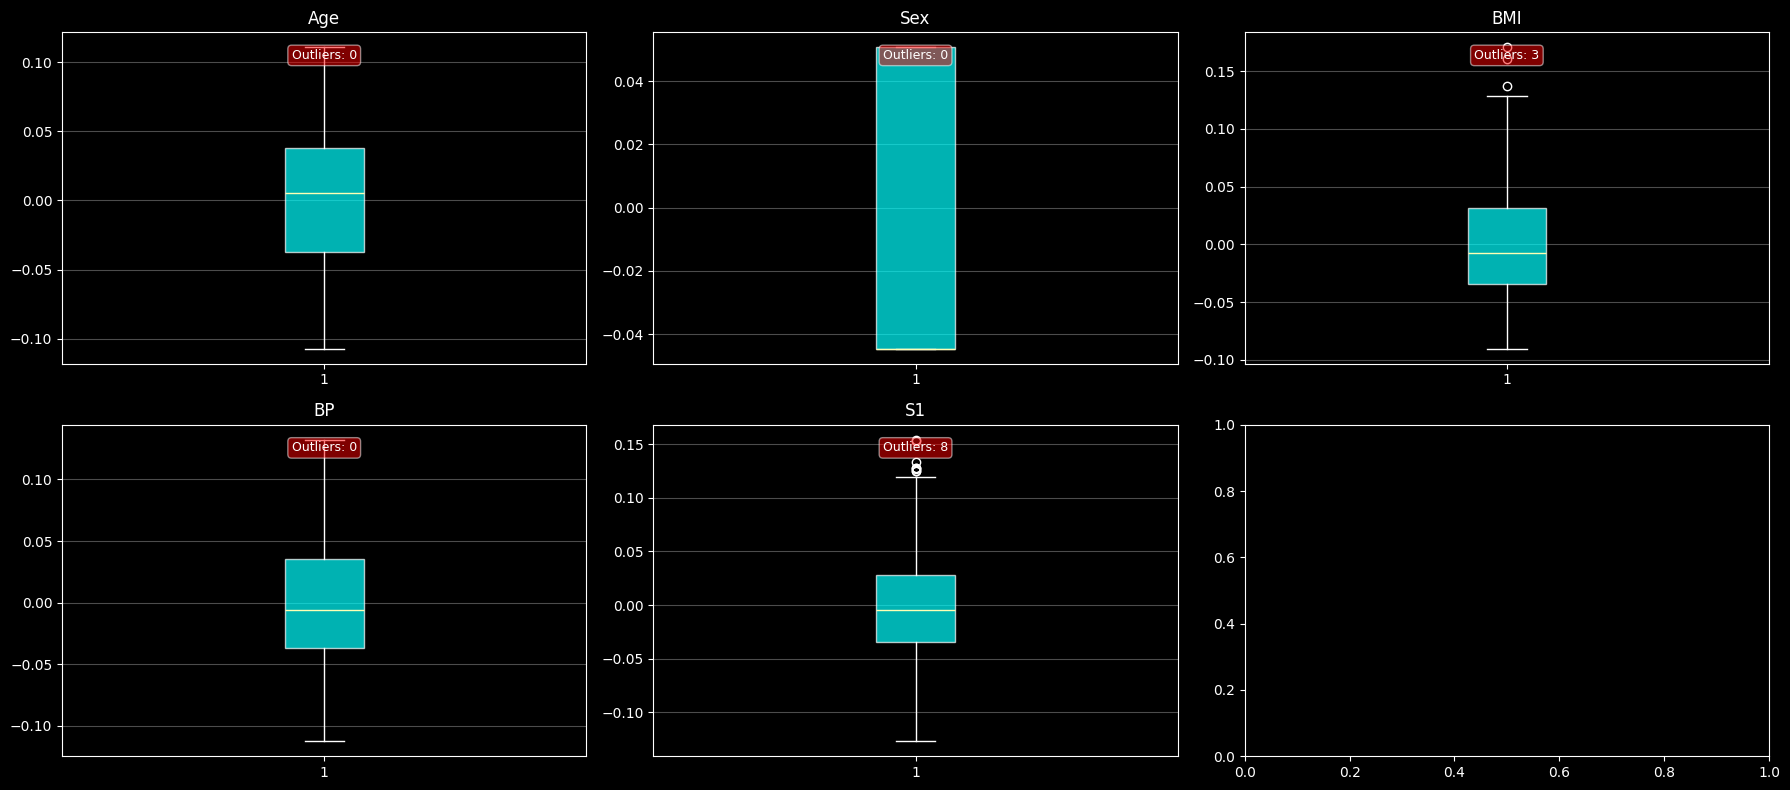

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(df_diabetes.columns):
    bp = axes[i].boxplot([df_diabetes[col]], patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor("cyan")
        patch.set_alpha(0.7)
    axes[i].set_title(col)
    axes[i].grid(alpha=0.3, axis="y")
    
    Q1 = df_diabetes[col].quantile(0.25)
    Q3 = df_diabetes[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_diabetes[(df_diabetes[col] < lower_bound) | (df_diabetes[col] > upper_bound)][col].shape[0]
    # outliers = ((df_diabetes[col] < lower_bound) | (df_diabetes[col] > upper_bound)).sum()
    
    axes[i].text(0.5, 0.95, f'Outliers: {outliers}',
            transform=axes[i].transAxes, ha='center', va='top',
            bbox=dict(boxstyle='round', facecolor='red', alpha=0.5), fontsize=9)
    

plt.tight_layout()
plt.show()

In [18]:
print("✅ Exercise 1 passed!")

✅ Exercise 1 passed!


---

# 2. Correlation Analysis

**Correlation coefficient (r):**

- **r = 1:** Perfect positive correlation
- **r = 0:** No correlation
- **r = -1:** Perfect negative correlation

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$


In [28]:
# Compute Correlation Matrix
corr_matrix = df_housing.corr()

print("Correlation with Target (Price):")
print(corr_matrix["Price"].sort_values(ascending=False))

Correlation with Target (Price):
Price         1.000000
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: Price, dtype: float64


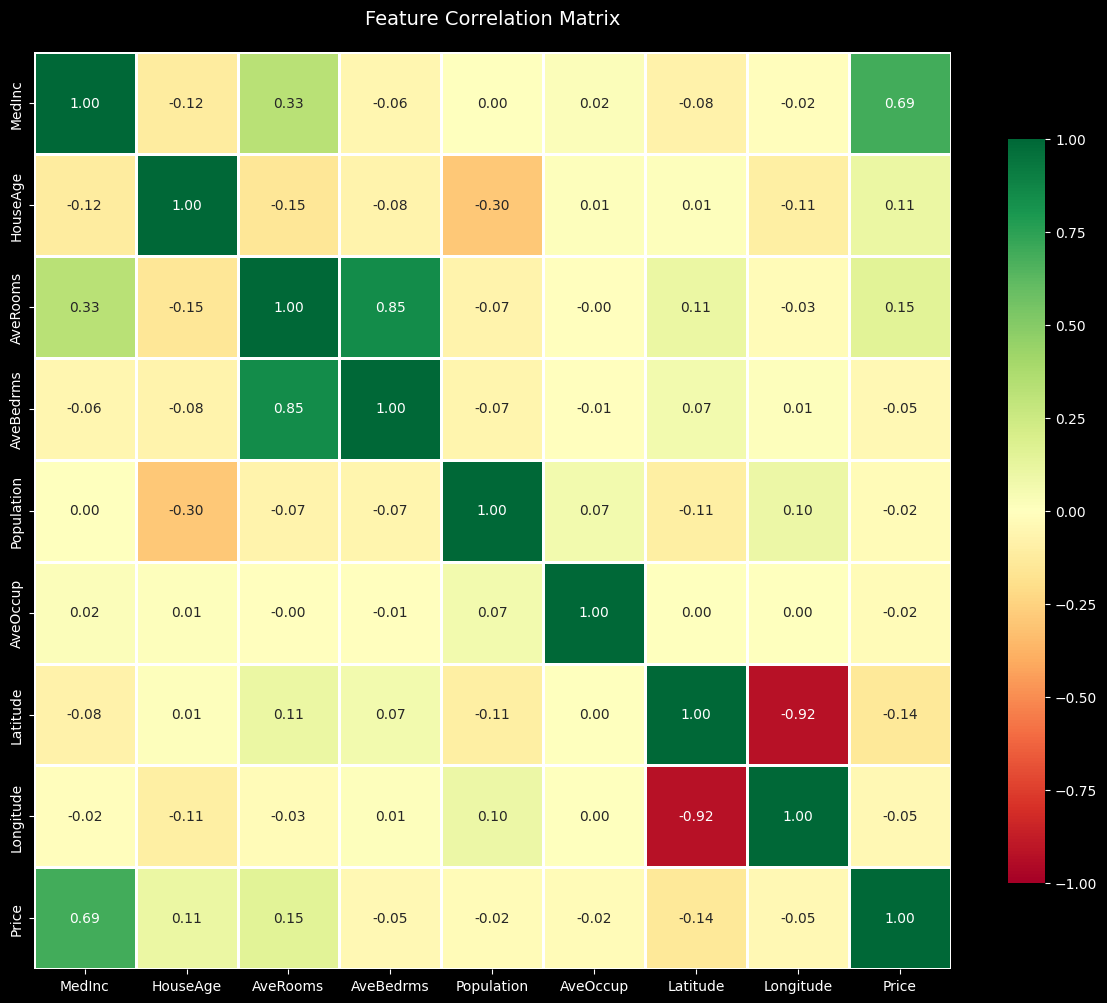

In [32]:
# Correlation heatmap .. note how the color reflects the value (use the colorbar on the right as the reference)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1, ax=ax)
ax.set_title('Feature Correlation Matrix', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

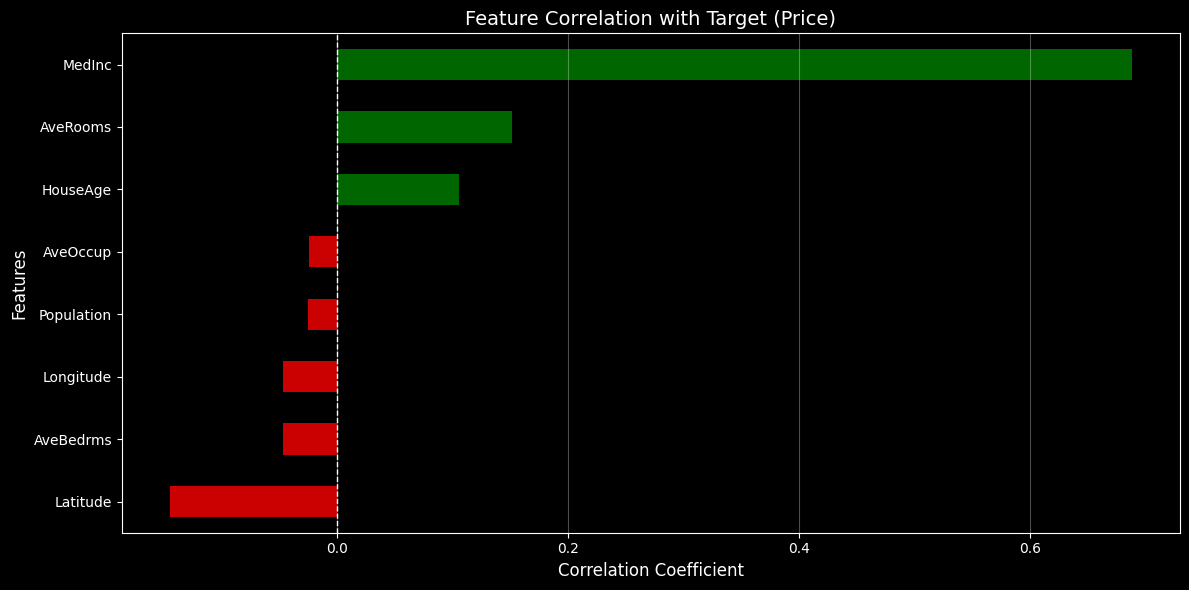

In [45]:
# Target correlation bar plot, see how we can use this plot to visualise correlation values
fig, ax = plt.subplots(figsize=(12, 6))
target_corr = corr_matrix["Price"].drop("Price").sort_values()
colors = ["red" if i < 0 else "green" for i in target_corr]
target_corr.plot(kind="barh", color=colors, ax=ax, alpha=0.8)
ax.set_xlabel('Correlation Coefficient', fontsize=12)
ax.set_ylabel('Features', fontsize=12)
ax.set_title('Feature Correlation with Target (Price)', fontsize=14)
ax.axvline(0, color='white', linestyle='--', linewidth=1)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

### Exercise 2: Find Highly Correlated Features

**Task:** Identify all feature pairs with |correlation| > 0.7


In [ ]:
# YOUR TASK: Find highly correlated pairs
# YOUR CODE HERE

corr_matrix_housing = df_housing.corr()[df_housing.corr() > 0.7]

upper_tri_mask = np.triu(np.ones_like(corr_matrix_housing, dtype=bool), k = 1)
upper_tri_mask = corr_matrix_housing.where(upper_tri_mask)

high_corr_pairs = upper_tri_mask.stack()
print(f"\nFound {len(high_corr_pairs)} highly correlated pairs")


Found 1 highly correlated pairs


In [125]:
corr_matrix_housing = df_housing.corr()[df_housing.corr() > 0.7]

high_corr_pairs = 0

for i in corr_matrix_housing:
    for j in corr_matrix_housing[i]:
        if j > 0.7 and j != 1:
            high_corr_pairs += 1

high_corr_pairs = int(high_corr_pairs / 2)

print(f"\nFound {high_corr_pairs} highly correlated pairs")


Found 1 highly correlated pairs


In [138]:
corr_matrix_housing = df_housing.corr()[df_housing.corr() > 0.7].stack()

high_corr_pairs = int(len(corr_matrix_housing[corr_matrix_housing != 1]) / 2)

print(f"\nFound {high_corr_pairs} highly correlated pairs")



Found 1 highly correlated pairs


In [140]:
corr_matrix_housing = df_housing.corr()[(df_housing.corr() > 0.7) & (df_housing.corr() != 1)].stack()
high_corr_pairs = int(len(corr_matrix_housing) / 2)

print(f"\nFound {high_corr_pairs} highly correlated pairs")



Found 1 highly correlated pairs


In [75]:
print("✅ Exercise 2 passed!")

✅ Exercise 2 passed!


---

# 3. Multicollinearity Detection

**Multicollinearity:** When features are highly correlated with each other

**Problems it causes:**

1. Unstable coefficient estimates
2. High variance in predictions
3. Difficulty interpreting feature importance

**Detection Methods: we can visually inspect correlations to detect it and we can also use Variance Inflation Factor (VIF)**

$$VIF_i = \frac{1}{1 - R_i^2} = \frac{SST}{SSR}$$

Where $R_i^2$ is the R² from regressing feature $i$ on all other features.

**Rule of thumb:**

- VIF = 1: No Correlation
- 1 < VIF < 5: Moderate multicollinearity (usually Acceptable)
- VIF >= 5 or 10: High multicollinearity (problematic!)

VIF won't be able to tell which feature correlated with which.


In [ ]:
def compute_vif(X):
    """Compute VIF for each feature"""
    vif_data = []

    for i in range(X.shape[1]):
        # Use all other features to predict feature i
        X_i = X[:, i]
        X_others = np.delete(X, i, axis=1)

        # Fit Linear Regression
        lr = LinearRegression()
        lr.fit(X_others, X_i)

        # Compute R²
        r_squared = lr.score(X_others, X_i)

        vif = 1 / (1 - r_squared) if r_squared < 0.999 else np.inf
        vif_data.append(vif)

    return np.array(vif_data)

X_housing = housing.data
vif_data = compute_vif(X_housing)

print("Feature                VIF")
print("-" * 35)
for feature, vif in zip(housing.feature_names, vif_data):
    print(f"{feature:15s} {vif:10.2f}")

Feature                VIF
-----------------------------------
MedInc                2.50
HouseAge              1.24
AveRooms              8.34
AveBedrms             6.99
Population            1.14
AveOccup              1.01
Latitude              9.30
Longitude             8.96


In [190]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

X_housing = housing.data
X_df = pd.DataFrame(X_housing, columns=housing.feature_names)

# Add the intercept constant (statsmodels requires this to calculate R^2 correctly)
X_with_const = add_constant(X_df)

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["Feature"] = X_with_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_with_const.values, i)
                   for i in range(X_with_const.shape[1])]

print(f"{'Feature':15s} {'VIF':>10s}")
print("-" * 35)

vif_clean = vif_data[vif_data["Feature"] != "const"]
for _, row in vif_clean.iterrows():
    print(f"{row['Feature']:15s} {row['VIF']:10.2f}")

Feature                VIF
-----------------------------------
MedInc                2.50
HouseAge              1.24
AveRooms              8.34
AveBedrms             6.99
Population            1.14
AveOccup              1.01
Latitude              9.30
Longitude             8.96


In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Scale the features to ensure kappa reflects collinearity, not scale differences
X_housing = housing.data

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_housing)

# 2. Compute the X^T X matrix (the Gram matrix)
XTX = np.dot(X_scaled.T, X_scaled)

# 3. Calculate the eigenvalues (\lambda) of X^T X
eigenvalues = np.linalg.eigvals(XTX)

# 4. Extract the maximum and minimum eigenvalues
lambda_max = np.max(eigenvalues)
lambda_min = np.min(eigenvalues)

# 5. Compute the Condition Number (\kappa) using the formula
kappa = np.sqrt(lambda_max / lambda_min)

print(f"Maximum Eigenvalue (\lambda_max): {lambda_max:.4f}")
print(f"Minimum Eigenvalue (\lambda_min): {lambda_min:.4f}")
print(f"Condition Number (\kappa):       {kappa:.4f}\n")

# 6. Evaluate against the instability threshold
if kappa > 30:
    print("Diagnostic: Severe multicollinearity detected (\kappa > 30).")
    print("The matrix is highly unstable.")
else:
    print("Diagnostic: Matrix is numerically stable (\kappa <= 30).")

Maximum Eigenvalue (\lambda_max): 41836.2361
Minimum Eigenvalue (\lambda_min): 940.8770
Condition Number (\kappa):       6.6682

Diagnostic: Matrix is numerically stable (\kappa <= 30).


### Exercise 3: Compute VIF

**Task:** Compute VIF for the Diabetes dataset features.


In [188]:
# Load diabetes data
diabetes = load_diabetes()
X_diabetes = diabetes.data[:, :5]  # Use first 5 features
feature_names_diabetes = ['Age', 'Sex', 'BMI', 'BP', 'S1']

print(f"Diabetes features: {feature_names_diabetes}")

Diabetes features: ['Age', 'Sex', 'BMI', 'BP', 'S1']


In [211]:
# YOUR TASK: Compute VIF for diabetes features
# YOUR CODE HERE
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

X_diabetes_df = pd.DataFrame(X_diabetes, columns=feature_names_diabetes)
X_add_const = add_constant(X_diabetes_df)

vif_df = pd.DataFrame()
vif_df["Feature"] = X_add_const.columns
vif_df["VIF"] = [variance_inflation_factor(X_add_const.values, i)
                 for i in range(X_add_const.shape[1])]

vif_df = vif_df[vif_df["Feature"] != "const"]

print(vif_df)

  Feature       VIF
1     Age  1.186503
2     Sex  1.075026
3     BMI  1.222773
4      BP  1.358962
5      S1  1.137553


In [214]:
vif_diabetes_data = compute_vif(X_diabetes)

print("Feature                VIF")
print("-" * 35)
for feature, vif_value in zip(feature_names_diabetes, vif_diabetes_data):
    print(f"{feature:15s} {vif_value:10.5f}")

Feature                VIF
-----------------------------------
Age                1.18650
Sex                1.07503
BMI                1.22277
BP                 1.35896
S1                 1.13755


In [215]:
print("✅ Exercise 3 passed!")

✅ Exercise 3 passed!


---

# 4. Handling Multicollinearity

Remove highly correlated features


In [217]:
# Create dataset with SEVERE multicollinearity
np.random.seed(42)
n = 500

# Base feature
x1 = np.random.randn(n)

# Highly correlated features
x2 = x1 + np.random.randn(n) * 0.1  # Almost identical to x1
x3 = 2 * x1 + np.random.randn(n) * 0.1  # Linear combination of x1
x4 = np.random.randn(n)  # Independent feature

# Target depends on x1 and x4
y = 3 * x1 + 2 * x4 + np.random.randn(n) * 0.5

X_multicol = np.column_stack([x1, x2, x3, x4])
feature_names_demo = ['X1', 'X2 (≈X1)', 'X3 (≈2×X1)', 'X4']

# Check correlations
corr_demo = np.corrcoef(X_multicol.T)
print("Correlation Matrix:")
print("        ", "  ".join(f"{name:12s}" for name in feature_names_demo))
for i, name in enumerate(feature_names_demo):
    print(f"{name:8s}", "  ".join(f"{corr_demo[i,j]:12.3f}" for j in range(4)))

Correlation Matrix:
         X1            X2 (≈X1)      X3 (≈2×X1)    X4          
X1              1.000         0.995         0.999         0.064
X2 (≈X1)        0.995         1.000         0.994         0.062
X3 (≈2×X1)        0.999         0.994         1.000         0.063
X4              0.064         0.062         0.063         1.000


### One way to address this issue is to remove correlated features:


In [218]:
# Remove features with correlation > 0.9
def remove_correlated_features(X, feature_names, threshold=0.9):
    """Remove features with correlation > threshold"""
    corr = np.corrcoef(X.T)
    to_remove = set()

    for i in range(len(feature_names)):
        for j in range(i+1, len(feature_names)):
            if abs(corr[i, j]) > threshold and j not in to_remove:
                to_remove.add(j)
                print(f"  Removing {feature_names[j]} (corr with {feature_names[i]}: {corr[i,j]:.3f})")

    keep_indices = [i for i in range(len(feature_names)) if i not in to_remove]
    return X[:, keep_indices], [feature_names[i] for i in keep_indices]


X_reduced, names_reduced = remove_correlated_features(X_multicol, feature_names_demo, threshold=0.9)
print(f"\nReduced from {X_multicol.shape[1]} to {X_reduced.shape[1]} features")
print(f"Remaining: {names_reduced}")

  Removing X2 (≈X1) (corr with X1: 0.995)
  Removing X3 (≈2×X1) (corr with X1: 0.999)

Reduced from 4 to 2 features
Remaining: ['X1', 'X4']


---

## Summary

✅ **Data Visualization:**

- Histograms reveal distributions
- Box plots detect outliers
- Scatter matrices show relationships

✅ **Correlation Analysis:**

- Identify feature-target relationships
- Find redundant features

✅ **Multicollinearity Detection:**

- Use correlation matrix
- Compute VIF

✅ **Handling Multicollinearity:**

- Remove correlated features
